# 05 - Training

Training of the convolutional-recurrent classifier (`wqu.models.cred`) on one representation, with the parameters of
the `training` and `model` sections of `configs/default.yaml`:
- input standardized per frequency with mean and standard deviation of the training records;
- weighted BCE loss, bad-class weight `n_good / n_bad` of the training records;
- Adam, learning rate reduced on plateau of the validation loss, early stopping, best model kept;
- per-epoch history (loss, AUC, balanced accuracy, ECE, learning rate) and its figures;
- MC dropout predictions on the validation set.

Every run writes to its own folder `training.runs_dir/<representation>_<date>_<time>/`: copy of the configuration,
normalization statistics, `history.csv` (updated at every epoch), `best_model.pt`, figures and validation predictions.

The training metrics are computed on the outputs produced while training (dropout active, weights changing within the
epoch), the validation metrics on a deterministic pass at the end of the epoch: with strong dropout the training loss can
stay above the validation loss without any anomaly.

## 0. Setup

In [1]:
from pathlib import Path

import pandas as pd

from wqu.config import load_config
from wqu.data.loading import CV_COMPONENTS
from wqu.data.splitting import SPLIT_COLUMN, TRAIN, VALIDATION, attach_split, load_split
from wqu.models.cred import build_model
from wqu.models.loss import bad_class_weight, prior_corrected_probability, weighted_bce_loss
from wqu.models.uncertainty import mc_dropout_predictions, uncertainty_summary
from wqu.preprocessing.pipeline import FEATURE_INDEX_COLUMN, feature_file_path, read_feature_records
from wqu.training.data import FeatureDataset, frequency_statistics, make_loader
from wqu.training.metrics import classification_metrics
from wqu.training.trainer import create_run_dir, epoch_metrics, evaluate, fit, select_device, set_seed
from wqu.visualization import apply_plot_style, plot_training_curve, plot_training_history, save_figure
import matplotlib.pyplot as plt

CONFIG_PATH = Path("..") / "configs" / "default.yaml"

config = load_config(CONFIG_PATH)
columns = config.columns
training = config.training
apply_plot_style()
set_seed(training.random_seed)
device = select_device(training.device)

features_path = feature_file_path(config.preprocessing, training.feature_source)
records = read_feature_records(features_path, columns.text)
records[SPLIT_COLUMN] = attach_split(records, load_split(config.split.output_file, columns), columns)
print(f"Feature file: {features_path} ({len(records):,} records); representation: {training.representation}; "
      f"device: {device}")

/Users/giulianaparadiso/miniconda3/envs/wqu/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Feature file: /Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/data/processed/dev_subset/features.h5 (2,000 records); representation: scalogram; device: mps


/var/folders/w_/v957zs393c5dg1q6n0kpt_pr0000gn/T/ipykernel_9200/4251530501.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  records[SPLIT_COLUMN] = attach_split(records, load_split(config.split.output_file, columns), columns)


## 1. Data

Per-frequency statistics from the training records only, bad-class weight from the training labels.

In [2]:
train_records = records[records[SPLIT_COLUMN] == TRAIN]
validation_records = records[records[SPLIT_COLUMN] == VALIDATION]
statistics = frequency_statistics(features_path, training.representation, train_records[FEATURE_INDEX_COLUMN].to_numpy())
bad_weight = bad_class_weight(train_records[columns.label].to_numpy())

run_dir = create_run_dir(training.runs_dir, training.representation, CONFIG_PATH)
statistics.save(run_dir / "normalization.npz")


def loader_for(subset: pd.DataFrame, shuffle: bool):
    """Loader of standardized images for a subset of the records."""
    dataset = FeatureDataset(features_path, training.representation, subset[FEATURE_INDEX_COLUMN].to_numpy(),
                             subset[columns.label].to_numpy(), statistics)
    return make_loader(dataset, training.batch_size, shuffle, training.num_workers, training.random_seed)


train_loader = loader_for(train_records, shuffle=True)
validation_loader = loader_for(validation_records, shuffle=False)
summary = records.groupby(SPLIT_COLUMN)[columns.label].agg(records="size", bad_rate="mean")
print(f"Run folder: {run_dir}")
print(f"Bad-class weight: {bad_weight:.3f}")
summary.round(3)

Run folder: /Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/runs/scalogram_20261110_184459
Bad-class weight: 0.995


,records,bad_rate
split,,
train,1600,0.501
validation,400,0.495


## 2. Training

The progress is printed at every epoch; `history.csv` in the run folder is rewritten at every epoch, so the run can be
followed from outside the notebook.

In [3]:
model = build_model(config.model, len(CV_COMPONENTS), len(statistics.mean))
result = fit(model, train_loader, validation_loader, weighted_bce_loss(bad_weight), training, bad_weight, run_dir, device)
history = result.history
print(f"Best epoch: {result.best_epoch} of {len(history)}; stopped early: {result.stopped_early}; "
      f"total time {history['seconds'].sum() / 60:.1f} min")
history.round(4)

epoch   1  train loss 0.6497  validation loss 0.5618  validation AUC 0.8152  lr 1.0e-03  3 s  (best)
epoch   2  train loss 0.5342  validation loss 0.5116  validation AUC 0.8307  lr 1.0e-03  2 s  (best)
epoch   3  train loss 0.4946  validation loss 0.5014  validation AUC 0.8510  lr 1.0e-03  2 s  (best)
epoch   4  train loss 0.4829  validation loss 0.4871  validation AUC 0.8552  lr 1.0e-03  2 s  (best)
epoch   5  train loss 0.4593  validation loss 0.4945  validation AUC 0.8473  lr 1.0e-03  2 s
epoch   6  train loss 0.4573  validation loss 0.4621  validation AUC 0.8628  lr 1.0e-03  2 s  (best)
epoch   7  train loss 0.4512  validation loss 0.4785  validation AUC 0.8543  lr 1.0e-03  2 s
epoch   8  train loss 0.4419  validation loss 0.4600  validation AUC 0.8648  lr 1.0e-03  2 s  (best)
epoch   9  train loss 0.4318  validation loss 0.4589  validation AUC 0.8653  lr 1.0e-03  2 s  (best)
epoch  10  train loss 0.4232  validation loss 0.4681  validation AUC 0.8691  lr 1.0e-03  2 s
epoch  11  tra

,epoch,learning_rate,train_loss,validation_loss,train_auc,train_balanced_accuracy,train_ece,validation_auc,validation_balanced_accuracy,validation_ece,seconds
0,1,0.0010,0.6497,0.5618,0.6816,0.6310,0.0492,0.8152,0.7062,0.1086,3.3833
1,2,0.0010,0.5342,0.5116,0.8131,0.7576,0.0528,0.8307,0.7470,0.0619,1.7843
2,3,0.0010,0.4946,0.5014,0.8365,0.7670,0.0295,0.8510,0.7585,0.0901,1.7622
3,4,0.0010,0.4829,0.4871,0.8508,0.7727,0.0371,0.8552,0.7880,0.0807,1.7250
4,5,0.0010,0.4593,0.4945,0.8639,0.7869,0.0362,0.8473,0.7668,0.0714,1.7451
5,6,0.0010,0.4573,0.4621,0.8657,0.7938,0.0248,0.8628,0.7946,0.0580,1.7225
6,7,0.0010,0.4512,0.4785,0.8690,0.7951,0.0267,0.8543,0.7775,0.0584,1.7281
7,8,0.0010,0.4419,0.4600,0.8746,0.7957,0.0248,0.8648,0.7997,0.0397,1.7075
8,9,0.0010,0.4318,0.4589,0.8819,0.8107,0.0376,0.8653,0.7823,0.0653,1.7467
9,10,0.0010,0.4232,0.4681,0.8869,0.8069,0.0388,0.8691,0.7754,0.0778,1.8062


## 3. Training curves

Overview (loss and learning rate on top; AUC, balanced accuracy and ECE below) and the loss alone. The dashed line marks
the epoch of the saved model.

PosixPath('/Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/runs/scalogram_20261110_184459/figures/training_loss.pdf')

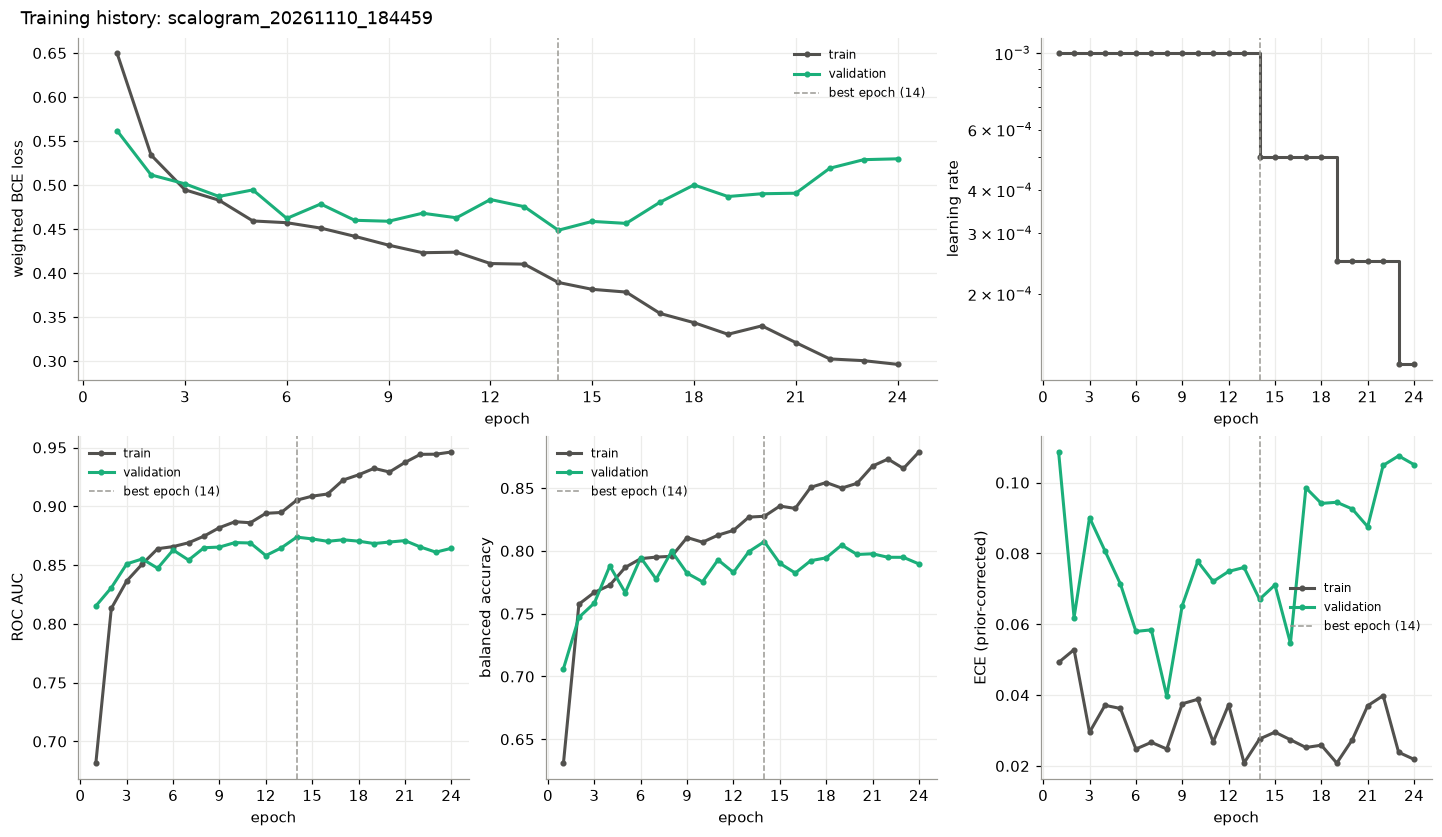

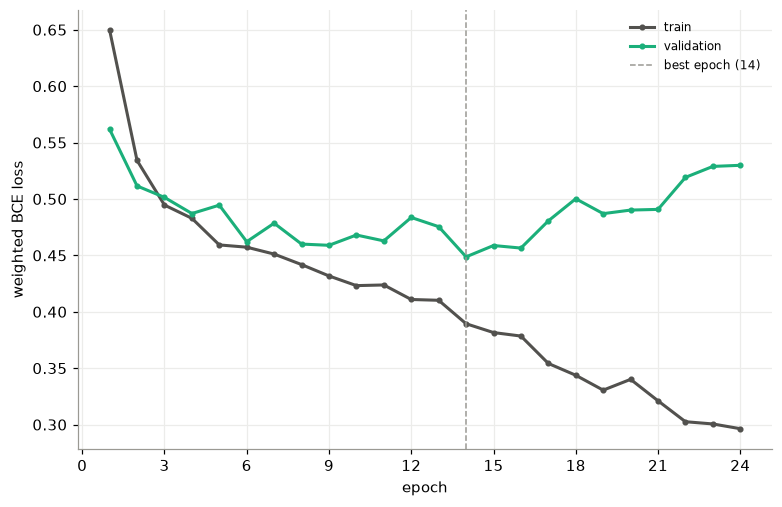

In [4]:
figures_dir = run_dir / "figures"
overview = plot_training_history(history, result.best_epoch, f"Training history: {run_dir.name}")
save_figure(overview, figures_dir / "training_history.png")
save_figure(overview, figures_dir / "training_history.pdf")

loss_figure, loss_ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
plot_training_curve(history, "loss", result.best_epoch, loss_ax)
save_figure(loss_figure, figures_dir / "training_loss.png")
save_figure(loss_figure, figures_dir / "training_loss.pdf")

## 4. Validation predictions with MC dropout

`model.mc_samples` stochastic passes per record. Per record: mean and standard deviation of the probability of the bad
class, predictive entropy and its split into aleatoric part and mutual information (epistemic part). The mean probability
is also given corrected to the class frequencies of the training set. The metrics of the MC mean are compared with those
of the deterministic pass of the saved model.

In [5]:
samples = mc_dropout_predictions(model, validation_loader, config.model.mc_samples, device)
predictions = uncertainty_summary(samples)
predictions.insert(0, "record", validation_records.index.to_numpy())
predictions.insert(1, columns.label, validation_records[columns.label].to_numpy())
predictions.insert(3, "probability_corrected", prior_corrected_probability(predictions["probability_mean"].to_numpy(), bad_weight))
predictions.to_csv(run_dir / "validation_predictions.csv", index=False)

labels = validation_records[columns.label].to_numpy()
_, deterministic_logits, _ = evaluate(model, validation_loader, weighted_bce_loss(bad_weight).to(device), device)
mc_metrics = classification_metrics(predictions["probability_mean"].to_numpy(), labels, training.calibration_bins)
mc_metrics["ece"] = classification_metrics(predictions["probability_corrected"].to_numpy(), labels,
                                           training.calibration_bins)["ece"]
comparison = pd.DataFrame({
    "deterministic": epoch_metrics(deterministic_logits, labels, bad_weight, training.calibration_bins),
    f"mc_dropout_{config.model.mc_samples}": mc_metrics,
})
comparison.to_csv(run_dir / "validation_metrics.csv")
comparison.round(4)

,deterministic,mc_dropout_50
auc,0.8738,0.8739
balanced_accuracy,0.8074,0.8074
ece,0.0671,0.0507


In [6]:
predictions.groupby(columns.label)[["probability_mean", "probability_std", "predictive_entropy",
                                     "mutual_information"]].describe().T.round(4)

label                            0         1
probability_mean   count  202.0000  198.0000
                   mean     0.2754    0.7269
                   std      0.2393    0.2738
                   min      0.0240    0.0425
                   25%      0.0948    0.5565
                   50%      0.1907    0.8302
                   75%      0.3691    0.9485
                   max      0.9641    0.9854
probability_std    count  202.0000  198.0000
                   mean     0.0736    0.0664
                   std      0.0338    0.0412
                   min      0.0221    0.0090
                   25%      0.0528    0.0329
                   50%      0.0685    0.0598
                   75%      0.0869    0.0831
                   max      0.2545    0.1788
predictive_entropy count  202.0000  198.0000
                   mean     0.4456    0.3931
                   std      0.1724    0.2019
                   min      0.1131    0.0763
                   25%      0.2995    0.2014
                   50%      0.4483    0.3873
                   75%      0.6033    0.5845
                   max      0.6931    0.6929
mutual_information count  202.0000  198.0000
                   mean     0.0207    0.0192
                   std      0.0149    0.0159
                   min      0.0056    0.0025
                   25%      0.0125    0.0091
                   50%      0.0170    0.0136
                   75%      0.0231    0.0218
                   max      0.1429    0.0856